# Detection benchmark: YOLOv8n vs YOLOv10n vs YOLO11n vs YOLO12n

Original experiment notebook for the plate detector comparison (5-epoch express run, then full training). Outputs are kept as recorded.


##Установка зависимостей

In [1]:
!pip install ultralytics>=8.0.0 opencv-python-headless>=4.8 pandas tqdm

##GPU

In [2]:
import torch
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

CUDA доступна: True
GPU: Tesla T4


##Dataset

In [2]:
from ultralytics.utils.downloads import download
from pathlib import Path
data_dir = Path("/content/datasets/coco")
data_dir.mkdir(parents=True, exist_ok=True)
print("Скачивание COCO val2017...")
url_val = "http://images.cocodataset.org/zips/val2017.zip"
download([url_val], dir=data_dir / "images", threads=3)
print("Скачивание аннотаций...")
url_labels = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco2017labels.zip"
download([url_labels], dir=data_dir.parent)
print("✓ Датасет готов!")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Скачивание COCO val2017...
Unzipping /content/datasets/coco/images/val2017.zip to /content/datasets/coco/images/val2017...: 100% ━━━━━━━━━━━━ 5001/5001 870.9files/s 5.7s
Скачивание аннотаций...
WARNING ⚠️ Skipping /content/datasets/coco2017labels.zip unzip as destination directory /content/datasets/coco is not empty.
✓ Датасет готов!


##Benchmark

In [4]:
import time
from pathlib import Path

import cv2
import pandas as pd
from tqdm import tqdm
from ultralytics import YOLO
import torch
import matplotlib.pyplot as plt


class DetectionBenchmark:
    def __init__(
        self,
        dataset_path,
        img_exts=(".jpg", ".jpeg", ".png"),
        device=None,
        imgsz=640,
        conf=0.25,
        iou=0.7,
        max_samples=200
    ):
        """
        dataset_path: путь к папке с изображениями (например, /content/datasets/coco/images/val2017)
        device: 'cuda', 'cpu' или None (авто)
        max_samples: ограничение числа изображений для быстрого теста
        """
        self.dataset_path = Path(dataset_path)
        self.img_exts = img_exts
        self.imgsz = imgsz
        self.conf = conf
        self.iou = iou
        self.max_samples = max_samples

        # ИНИЦИАЛИЗАЦИЯ device и results
        if device is None:
            self.device = "cuda" if torch.cuda.is_available() else "cpu"
        else:
            self.device = device

        print(f"Устройство для детекции: {self.device}")
        self.results = []

    def _load_images(self):
        images = []
        for ext in self.img_exts:
            images.extend(sorted(self.dataset_path.rglob(f"*{ext}")))
        if self.max_samples is not None:
            images = images[: self.max_samples]
        return images

    def benchmark_model(self, model_name: str):
        """
        model_name: 'yolov8n.pt', 'yolov8s.pt', ...
        """
        print("\n" + "=" * 60)
        print(f"Тестирование: {model_name}")
        print("=" * 60)

        try:
            model = YOLO(model_name)
            model.to(self.device)

            images = self._load_images()
            if not images:
                print(f"Нет изображений в {self.dataset_path}")
                return

            # "прогрев" модели
            dummy = cv2.imread(str(images[0]))
            _ = model.predict(
                dummy,
                imgsz=self.imgsz,
                conf=self.conf,
                iou=self.iou,
                verbose=False,
            )

            times = []
            for img_path in tqdm(images, desc=f"{model_name} inference"):
                img = cv2.imread(str(img_path))
                if img is None:
                    continue

                t0 = time.time()
                _ = model.predict(
                    img,
                    imgsz=self.imgsz,
                    conf=self.conf,
                    iou=self.iou,
                    verbose=False,
                    device=self.device,
                    classes=None,  # можно указать классы автомобилей, если есть
                )
                t1 = time.time()
                times.append(t1 - t0)

            if times:
                avg_time = sum(times) / len(times)
                fps = 1.0 / avg_time
                print(f"Среднее время на кадр: {avg_time * 1000:.2f} ms, FPS: {fps:.2f}")
            else:
                avg_time, fps = None, None
                print("Нет корректно обработанных изображений.")

            # Сохраняем результат, чтобы save_results() не падал
            self.results.append(
                {
                    "model": model_name,
                    "avg_time_ms": None if avg_time is None else avg_time * 1000,
                    "fps": fps,
                    "device": self.device,
                    "imgsz": self.imgsz,
                    "n_images": len(times),
                }
            )

        except Exception as e:
            print(f"Ошибка при тестировании {model_name}: {e}")
            # Даже при ошибке добавляем запись – будет видно, что модель не отработала
            self.results.append(
                {
                    "model": model_name,
                    "avg_time_ms": None,
                    "fps": None,
                    "device": self.device,
                    "imgsz": self.imgsz,
                    "n_images": 0,
                    "error": str(e),
                }
            )

    def run_benchmark(self, model_names=None):
        if model_names is None:
            model_names = ["yolov8n.pt", "yolov8s.pt", "yolov8m.pt", "yolov8l.pt"]

        for name in model_names:
            self.benchmark_model(name)

        self.save_results()

    def save_results(self, csv_path="yolov8_benchmark_results.csv"):
        if not self.results:
            print("Нет результатов для сохранения.")
            return

        df = pd.DataFrame(self.results)
        df.to_csv(csv_path, index=False)
        print(f"\nРезультаты сохранены в {csv_path}")
        print(df)

        self.plot_results(df)

    def plot_results(self, df: pd.DataFrame, out_path="yolov8_benchmark_charts.png"):
        """Построить графики FPS и времени на кадр"""
        # фильтруем только успешные модели
        df_plot = df[df["avg_time_ms"].notna()].copy()
        if df_plot.empty:
            print("Нет данных для построения графиков.")
            return

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        fig.suptitle("Сравнение моделей YOLOv8 по скорости", fontsize=14, fontweight="bold")

        # FPS
        axes[0].bar(df_plot["model"], df_plot["fps"], color="steelblue")
        axes[0].set_title("FPS (кадров в секунду)")
        axes[0].set_ylabel("FPS")
        axes[0].tick_params(axis="x", rotation=20)

        # Время на кадр
        axes[1].bar(df_plot["model"], df_plot["avg_time_ms"], color="coral")
        axes[1].set_title("Среднее время на кадр")
        axes[1].set_ylabel("Время, ms")
        axes[1].tick_params(axis="x", rotation=20)

        plt.tight_layout()
        plt.savefig(out_path, dpi=300, bbox_inches="tight")
        print(f"\nГрафики сохранены в: {out_path}")
        plt.show()



##Запуск бенчмарка

Устройство для детекции: cuda

Тестирование: yolov8n.pt


yolov8n.pt inference: 100%|██████████| 200/200 [00:03<00:00, 60.78it/s]


Среднее время на кадр: 12.88 ms, FPS: 77.63

Тестирование: yolov8s.pt


yolov8s.pt inference: 100%|██████████| 200/200 [00:03<00:00, 52.02it/s]


Среднее время на кадр: 14.82 ms, FPS: 67.47

Тестирование: yolov8m.pt


yolov8m.pt inference: 100%|██████████| 200/200 [00:05<00:00, 36.36it/s]


Среднее время на кадр: 22.77 ms, FPS: 43.92

Тестирование: yolov8l.pt


yolov8l.pt inference: 100%|██████████| 200/200 [00:07<00:00, 26.76it/s]


Среднее время на кадр: 33.05 ms, FPS: 30.26

Результаты сохранены в yolov8_benchmark_results.csv
        model  avg_time_ms        fps device  imgsz  n_images
0  yolov8n.pt    12.882175  77.626640   cuda    640       200
1  yolov8s.pt    14.820397  67.474576   cuda    640       200
2  yolov8m.pt    22.768794  43.919761   cuda    640       200
3  yolov8l.pt    33.046778  30.260136   cuda    640       200

Графики сохранены в: yolov8_benchmark_charts.png


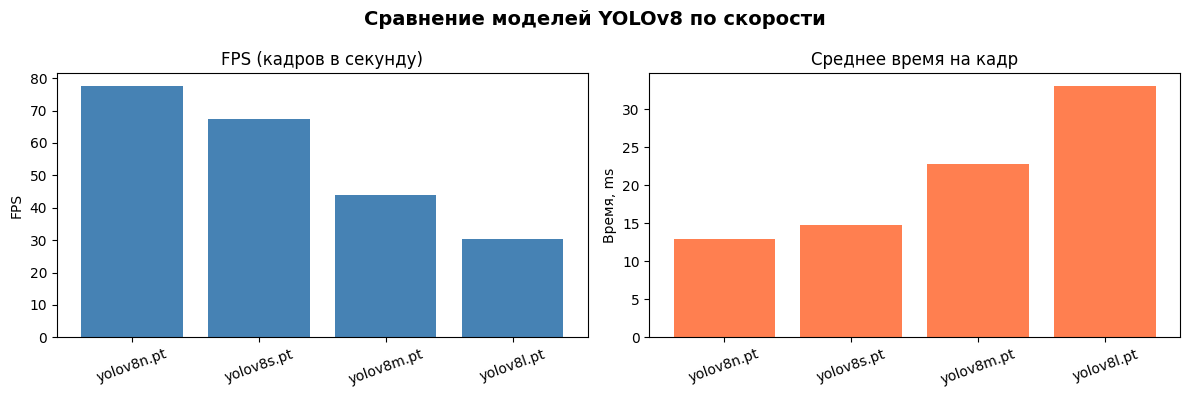

In [5]:
dataset_path = "/content/datasets/coco/images/val2017"  # или твой путь
benchmark = DetectionBenchmark(dataset_path=dataset_path, max_samples=200)
benchmark.run_benchmark()

In [ ]:
from google.colab import files
#files.download('detection_benchmark_results.csv')
files.download('detection_benchmark_charts.png')

##_cpu

In [ ]:
!pip install ultralytics>=8.0.0 opencv-python-headless>=4.8 pandas tqdm

import time
from pathlib import Path

import cv2
import pandas as pd
from tqdm import tqdm
from ultralytics import YOLO
import torch


class DetectionBenchmark:
    def __init__(
        self,
        dataset_path,
        img_exts=(".jpg", ".jpeg", ".png"),
        device=None,
        imgsz=640,
        conf=0.25,
        iou=0.7,
        max_samples=200
    ):
        """
        dataset_path: путь к папке с изображениями (например, /content/datasets/coco/images/val2017)
        device: 'cuda', 'cpu' или None (авто)
        max_samples: ограничение числа изображений для быстрого теста
        """
        self.dataset_path = Path(dataset_path)
        self.img_exts = img_exts
        self.imgsz = imgsz
        self.conf = conf
        self.iou = iou
        self.max_samples = max_samples

        # ИНИЦИАЛИЗАЦИЯ device и results
        if device is None:
            self.device = "cuda" if torch.cuda.is_available() else "cpu"
        else:
            self.device = device

        self.results = []

    def _load_images(self):
        images = []
        for ext in self.img_exts:
            images.extend(sorted(self.dataset_path.rglob(f"*{ext}")))
        if self.max_samples is not None:
            images = images[: self.max_samples]
        return images

    def benchmark_model(self, model_name: str):
        """
        model_name: 'yolov8n.pt', 'yolov8s.pt', ...
        """
        print("\n" + "=" * 60)
        print(f"Тестирование: {model_name}")
        print("=" * 60)

        try:
            model = YOLO(model_name)
            model.to(self.device)

            images = self._load_images()
            if not images:
                print(f"Нет изображений в {self.dataset_path}")
                return

            # "прогрев" модели
            dummy = cv2.imread(str(images[0]))
            _ = model.predict(dummy, imgsz=self.imgsz, conf=self.conf, iou=self.iou, verbose=False)

            times = []
            for img_path in tqdm(images, desc=f"{model_name} inference"):
                img = cv2.imread(str(img_path))
                if img is None:
                    continue

                t0 = time.time()
                _ = model.predict(
                    img,
                    imgsz=self.imgsz,
                    conf=self.conf,
                    iou=self.iou,
                    verbose=False,
                    device=self.device,
                    classes=None,  # можно указать классы автомобилей, если есть
                )
                t1 = time.time()
                times.append(t1 - t0)

            if times:
                avg_time = sum(times) / len(times)
                fps = 1.0 / avg_time
                print(f"Среднее время на кадр: {avg_time * 1000:.2f} ms, FPS: {fps:.2f}")
            else:
                avg_time, fps = None, None
                print("Нет корректно обработанных изображений.")

            # Сохраняем результат, чтобы save_results() не падал
            self.results.append(
                {
                    "model": model_name,
                    "avg_time_ms": None if avg_time is None else avg_time * 1000,
                    "fps": fps,
                    "device": self.device,
                    "imgsz": self.imgsz,
                    "n_images": len(times),
                }
            )

        except Exception as e:
            print(f"Ошибка при тестировании {model_name}: {e}")
            # Даже при ошибке добавляем запись – будет видно, что модель не отработала
            self.results.append(
                {
                    "model": model_name,
                    "avg_time_ms": None,
                    "fps": None,
                    "device": self.device,
                    "imgsz": self.imgsz,
                    "n_images": 0,
                    "error": str(e),
                }
            )

    def run_benchmark(self, model_names=None):
        if model_names is None:
            model_names = ["yolov8n.pt", "yolov8s.pt", "yolov8m.pt", "yolov8l.pt"]

        for name in model_names:
            self.benchmark_model(name)

        self.save_results()

    def save_results(self, csv_path="yolov8_benchmark_results.csv"):
        if not self.results:
            print("Нет результатов для сохранения.")
            return

        df = pd.DataFrame(self.results)
        df.to_csv(csv_path, index=False)
        print(f"\nРезультаты сохранены в {csv_path}")
        print(df)


In [ ]:
dataset_path = "/content/datasets/coco/images/val2017"  # или твой путь
benchmark = DetectionBenchmark(dataset_path=dataset_path, max_samples=200)
benchmark.run_benchmark()


Тестирование: yolov8n.pt


yolov8n.pt inference: 100%|██████████| 200/200 [00:41<00:00,  4.84it/s]


Среднее время на кадр: 199.58 ms, FPS: 5.01

Тестирование: yolov8s.pt


yolov8s.pt inference: 100%|██████████| 200/200 [01:32<00:00,  2.17it/s]


Среднее время на кадр: 453.82 ms, FPS: 2.20

Тестирование: yolov8m.pt


yolov8m.pt inference: 100%|██████████| 200/200 [03:39<00:00,  1.10s/it]


Среднее время на кадр: 1093.49 ms, FPS: 0.91

Тестирование: yolov8l.pt


yolov8l.pt inference: 100%|██████████| 200/200 [07:13<00:00,  2.17s/it]

Среднее время на кадр: 2158.77 ms, FPS: 0.46

Результаты сохранены в yolov8_benchmark_results.csv
        model  avg_time_ms       fps device  imgsz  n_images
0  yolov8n.pt   199.576795  5.010603    cpu    640       200
1  yolov8s.pt   453.815658  2.203538    cpu    640       200
2  yolov8m.pt  1093.492006  0.914501    cpu    640       200
3  yolov8l.pt  2158.771027  0.463227    cpu    640       200
